# Isolation

`Isolation Forest is an unsupervised anomaly-detection algorithm that identifies unusual data points by isolating them from the rest of the data.`


`Anomalies are easier t o isolate than normal observations.`

# for more info click the link below

https://docs.google.com/document/d/1lWmC7Yn0tvPbN6LLdAb3CESARMxr-DgRYJYKGgKa0rE/edit?usp=sharing

# Notes and interview Q & A

https://docs.google.com/document/d/1E0NokgVucHFs65g_YRVKBUXAAnqJKxxDJ8Fz_UeyN80/edit?usp=sharing

# CODING

In [2]:
import numpy as np                                      # Numerical calculations
import matplotlib.pyplot as plt                         # Visualization

from sklearn.datasets import make_blobs                 # Generate synthetic clustered data
from sklearn.ensemble import IsolationForest             # Isolation Forest anomaly detector

# Generate normal data 

In [3]:
X, _ = make_blobs(
    n_samples=500,                                      # Generate 500 normal observations
    centers=1,                                          # Create one main cluster
    cluster_std=1.0,                                    # Control the spread of the normal cluster
    random_state=42                                     # Make the generated data reproducible
)

print("Normal data shape:", X.shape)                    # 500 samples × 2 features

Normal data shape: (500, 2)


# Add anomalies 

`we aill create some points far away from the main cluster.`

In [4]:
anomalies = np.array([
    [8, 8],                                             # Artificial anomaly
    [9, 7],                                             # Artificial anomaly
    [8, -7],                                            # Artificial anomaly
    [-8, 8],                                            # Artificial anomaly
    [-7, -8]                                            # Artificial anomaly
])

X = np.vstack([
    X,                                                   # Normal observations
    anomalies                                            # Add anomalous observations
])

print("Final data shape:", X.shape)                     # 505 samples × 2 features

Final data shape: (505, 2)


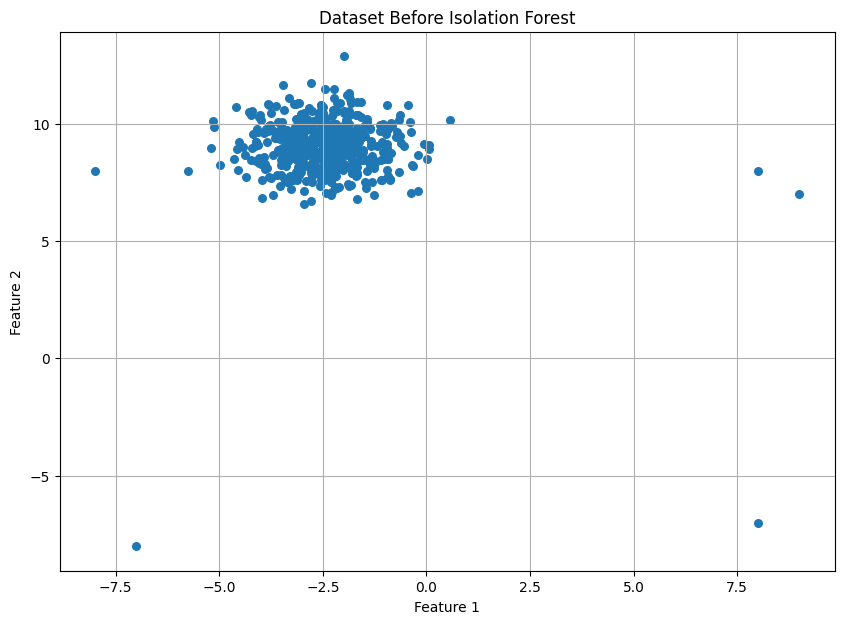

In [5]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X[:, 0],                                             # First feature
    X[:, 1],                                             # Second feature
    s=30                                                 # Point size
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Dataset Before Isolation Forest")

plt.grid()
plt.show()

# Create isolation forest 


In [6]:
isolation_forest = IsolationForest(
    n_estimators=100,                                    # Build 100 isolation trees
    contamination=0.01,                                  # Expect approximately 1% of observations to be anomalies
    random_state=42                                     # Make the result reproducible
)

# Fit isolation forest 

In [7]:
isolation_forest.fit(X)

IsolationForest(contamination=0.01, random_state=42)

# predict anomalies 

In [8]:
predictions = isolation_forest.predict(
    X                                                     # Classify each observation as normal or anomalous
)

print(predictions[:20])                                  # Display the first 20 predictions

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


# FInd the anomalies

In [9]:
anomaly_mask = predictions == -1                         # Create a Boolean mask for anomalous observations

X_anomalies = X[
    anomaly_mask                                         # Select only observations classified as anomalies
]

print("Detected anomalies:", len(X_anomalies))           # Number of detected anomalies

Detected anomalies: 6


# Visualize the detected anomalies 

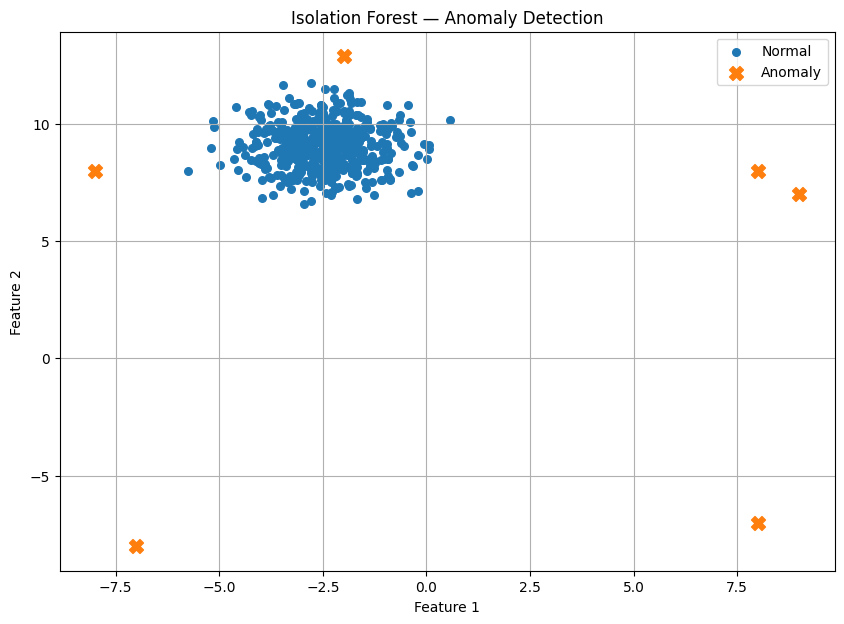

In [10]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X[:, 0],                                             # First feature
    X[:, 1],                                             # Second feature
    s=30,                                                # Normal point size
    label="Normal"
)

plt.scatter(
    X_anomalies[:, 0],                                   # First feature of anomalies
    X_anomalies[:, 1],                                   # Second feature of anomalies
    s=100,                                               # Make anomalies larger
    marker="X",                                          # Use X marker for anomalies
    label="Anomaly"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Isolation Forest — Anomaly Detection")

plt.legend()
plt.grid()
plt.show()

# decision_function()
`isolation forest can also provide an anomaly score .`


In [11]:
scores = isolation_forest.decision_function(
    X                                                     # Calculate the anomaly score for every observation
)

print(scores[:10])                                       # Display the first 10 anomaly scores

[0.05614551 0.26569606 0.25983945 0.25338533 0.13524408 0.26760017
 0.20831524 0.21618292 0.11222653 0.25869764]


# Experiment with n_estimators 

`This is one of the most important hyperparameters`


In [12]:
for n in [50, 100, 200, 500]:

    model = IsolationForest(
        n_estimators=n,                                  # Change the number of isolation trees
        contamination=0.01,                              # Keep expected anomaly proportion fixed
        random_state=42                                  # Keep comparison reproducible
    )

    model.fit(
        X                                                   # Train Isolation Forest
    )

    predictions = model.predict(
        X                                                   # Detect anomalies
    )

    print(
        f"n_estimators={n} → anomalies={sum(predictions == -1)}"
    )

n_estimators=50 → anomalies=6
n_estimators=100 → anomalies=6
n_estimators=200 → anomalies=6
n_estimators=500 → anomalies=6


# Experiment with contamination 

In [14]:
for contamination in [0.01, 0.02, 0.05, 0.10]:

    model = IsolationForest(
        n_estimators=200,                                # Use 200 isolation trees
        contamination=contamination,                     # Change expected anomaly proportion
        random_state=42                                  # Reproducible result
    )

    model.fit(
        X                                                   # Train the model
    )

    predictions = model.predict(
        X                                                   # Detect anomalies
    )

    print(
        f"contamination={contamination} → anomalies={sum(predictions == -1)}"
    )



# Remember 
#
# contamination
#     ↓
# Expected percentage of anomalies




contamination=0.01 → anomalies=6
contamination=0.02 → anomalies=11
contamination=0.05 → anomalies=26
contamination=0.1 → anomalies=51


| Parameter       | Meaning                                   |
| --------------- | ----------------------------------------- |
| `n_estimators`  | Number of isolation trees                 |
| `contamination` | Expected proportion of anomalies          |
| `max_samples`   | Number of samples used to build each tree |
| `max_features`  | Number of features considered             |
| `random_state`  | Reproducibility                           |


# Important output 

1 - Normal 

-1 - Anomaly 

In [15]:
model.predict(X)

array([-1,  1,  1,  1, -1,  1,  1,  1, -1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1, -1,  1,  1, -1,  1,  1,
       -1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1, -1,  1,  1, -1,  1, -1,  1,  1,  1,
       -1,  1,  1, -1,  1,  1,  1,  1, -1,  1,  1, -1,  1,  1,  1,  1,  1,
        1,  1,  1, -1,  1, -1,  1,  1,  1,  1,  1, -1,  1,  1,  1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1, -1,  1,  1,
        1,  1,  1, -1,  1,  1,  1, -1,  1,  1,  1,  1,  1,  1,  1,  1, -1,
        1,  1,  1,  1,  1, -1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
       -1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
       -1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1, -1,  1,  1,
        1,  1,  1,  1,  1,  1,  1,  1, -1,  1,  1,  1,  1,  1, -1,  1,  1,
        1,  1,  1,  1,  1